In [ ]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
transform = transforms.Compose([
 transforms.ToTensor(),
 transforms.Normalize((0.5,), (0.5,))])

In [ ]:
train_data = datasets.MNIST(root='./data', train=True, download=True,
transform=transform)
dataloader = DataLoader(train_data, batch_size=64, shuffle=True)

In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            nn.Linear(100, 256),
            nn.ReLU(True),
            nn.Linear(256, 512),
            nn.ReLU(True),
            nn.Linear(512, 1024),
            nn.ReLU(True),
            nn.Linear(1024, 784),
            nn.Tanh()
        )
    def forward(self, x):
        return self.main(x).view(-1, 1, 28, 28)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.main(x.view(-1, 784))

In [ ]:
generator = Generator()
discriminator = Discriminator()

In [ ]:
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

In [ ]:
epochs = 30
for epoch in range(epochs):
    for batch, (real_images, _) in enumerate(dataloader):
        batch_size = real_images.size(0)

In [ ]:
        real_labels = torch.ones(batch_size, 1)
        fake_labels = torch.zeros(batch_size, 1)
        # Train Discriminator
        outputs = discriminator(real_images)
        d_loss_real = criterion(outputs, real_labels)
        z = torch.randn(batch_size, 100)
        fake_images = generator(z)
        outputs = discriminator(fake_images.detach())
        d_loss_fake = criterion(outputs, fake_labels)
        d_loss = d_loss_real + d_loss_fake
        optimizer_d.zero_grad()
        d_loss.backward()
        optimizer_d.step()

In [ ]:
        z = torch.randn(batch_size, 100)
        fake_images = generator(z)
        outputs = discriminator(fake_images)
        g_loss = criterion(outputs, real_labels)
        optimizer_g.zero_grad()
        g_loss.backward()
        optimizer_g.step()
        print(f"Epoch [{epoch+1}/{epochs}], D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}")

Epoch [30/30], D Loss: 1.3987, G Loss: 0.7090


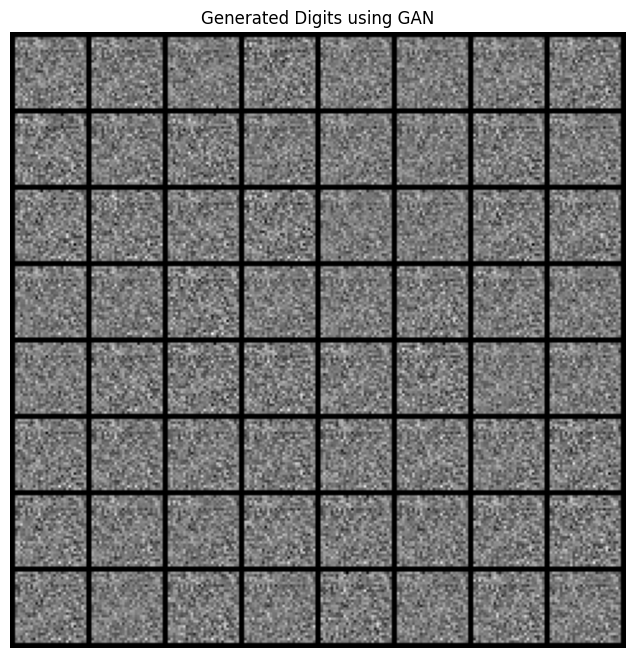

In [ ]:
import torchvision
z = torch.randn(64, 100)
generated_imgs = generator(z).detach()
grid = torchvision.utils.make_grid(generated_imgs, nrow=8, normalize=True)
plt.figure(figsize=(8,8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.title("Generated Digits using GAN")
plt.show()